In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.linalg import expm
from itertools import accumulate


In [2]:

def matrix_exponential_solution(T: float, kon: float, koff: float, x0: np.ndarray, dt: float, duration: float):
    #Convert duration to seconds
    duration = duration*60
    # Normalize x0
    x0 = x0/np.sum(x0)
    
    # Define the state transition matrix A
    A = np.array([
        [-kon*T, koff],
        [kon*T, -koff]
    ])
    
    # Time evolution
    num_timepoints = int(round(duration/dt))
    time = np.asarray(range(0,num_timepoints))*dt
    traces = np.array([expm(A*t) @ x0 for t in time])
    
    return x0, time, traces 


def plot_matrix_exponential_model(target_profile_list: list, fraction_bound_passive: np.ndarray, fraction_bound_active: np.ndarray, Kd: float, dt: float): 
    time = np.asarray(range(0,round(sum(60*sublist[1] for sublist in target_profile_list)/dt)))*dt
    
    target_profile = []
    equilibrium_fraction_profile = []
    labels = []
    step_lengths = []
    
    for step in target_profile_list:
        target_profile.extend([step[0]]*round(60*step[1]/dt))
        equilibrium_fraction = step[0]/(Kd+step[0])
        equilibrium_fraction_profile.extend([equilibrium_fraction]*round(60*step[1]/dt))
        labels.append(f"{step[0]:.2e} M")
        step_lengths.append(step[1])
    
    transition_times = [0] + list(accumulate(step_lengths))
    plt.figure(figsize=(12, 4))
    
    # plt.plot(time, fraction_bound_passive, label='fraction bound passive', linewidth=2.5, color='#0000FF')
    # plt.plot(time, fraction_bound_active, label='fraction bound active', linewidth=2.5, color='#E50000')
    # plt.scatter(time, equilibrium_fraction_profile, s=1, label='equilibrium fraction bound', linewidth=2.5, color='#15B01A')
    
    plt.plot(time, fraction_bound_passive, label='fraction bound passive', linewidth=2.5, color='#15B01A')
    plt.plot(time, equilibrium_fraction_profile, label='equilibrium fraction bound', linewidth=2.5, color='#0000FF', alpha=0.3)
    plt.plot(time, fraction_bound_active, label='fraction bound active', linewidth=2.5, color='#FFA500')
    #Add annotations at the top of the figure
    for i, label in enumerate(labels):
        plt.text(60*(transition_times[i]+transition_times[i+1])/2, 1.1*max(equilibrium_fraction_profile), label, ha='center', fontsize=8)

        plt.axvline(x=transition_times[i]*60, color='black', linestyle='--', linewidth=1)

    
    #plt.title('first order binding kinetics for single binder')
    plt.xlabel('time (s)')
    plt.ylabel('fraction bound', color='black')
    plt.legend(loc='center left')
    plt.grid()
    plt.ylim(0.00, 1.2*max(equilibrium_fraction_profile))
    
    # 
    # ax2 = plt.gca().twinx()
    # ax2.semilogy(time, target_profile, label='target', color='black')
    
    
    
    # ax2.set_ylabel('target concentration (M)')
    
 
    
    
    plt.show()
    
def il6_pg_mL_to_M(pgmL: float):
    mw_IL6 = 20e3 #Da

    molarity = (pgmL*1e-12/1e-3)/mw_IL6
    return molarity

def tnfa_pg_mL_to_M(pgmL: float):
    mw_TNFa = 17e3 #Da #or 52 for homotrimer?

    molarity = (pgmL*1e-12/1e-3)/mw_TNFa
    return molarity


        

In [44]:
figure5_concentration_profile_pgmL = [[50, 30], [100, 30], [200, 30], [200, 30], [300, 30], [500, 30], [400, 30], [100, 30], [10, 30], [10, 30]]
il6_figure5_concentration_profile_M = []
for step in figure5_concentration_profile_pgmL:
    molarity = il6_pg_mL_to_M(step[0])
    il6_figure5_concentration_profile_M.append([molarity, step[1]])

TNFa_figure5_concentration_profile_M = []
for step in figure5_concentration_profile_pgmL:
    molarity = tnfa_pg_mL_to_M(step[0])
    TNFa_figure5_concentration_profile_M.append([molarity, step[1]])

kon:  8300.0 koff:  0.000338 Kd:  4.072289156626506e-08


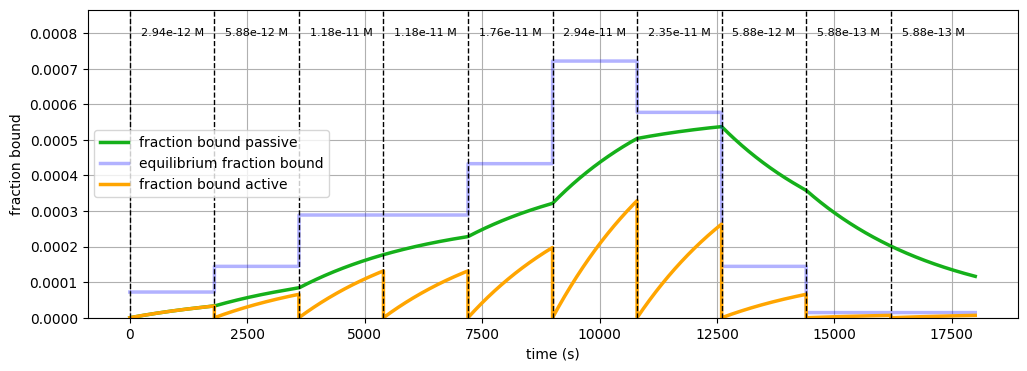

In [45]:
#IL-6 PBS:
# kon = 5.2e4 # 1/M*s
# koff = 2.84e-4 # 1/s

#IL-6 ISF:
# kon = 3.11e4 # 1/M*s
# koff = 1.61e-3 # 1/s

# TNF-alpha PBS:
# kon = 2.33e4
# koff = 1.22e-4

#TNF-alpha ISF:
kon = 8.3e3 # 1/M*s
koff = 3.38e-4 # 1/s

Kd = koff/kon # M
print("kon: ", kon, "koff: ", koff, "Kd: ", Kd)


target_profile_list = TNFa_figure5_concentration_profile_M #[[1e-13, 30], [1e-12, 30], [1e-11, 30], [7e-12, 30], [1e-13, 30]] # specify list of lists of pairs of target concentration and duration of that concentration

fraction_bound_passive = []
fraction_bound_active = []

timestep=0.5
x0 = [1, 0]
for step in target_profile_list:
    target = step[0] # M
    duration = step[1] # min
    _, _, traces = matrix_exponential_solution(T=target, kon=kon, koff= koff, x0=x0, dt=timestep, duration=duration)
    fraction_bound_passive.extend(traces[:,1].tolist())
    x0 = traces[-1,:]
    
x0 = [1, 0]
for step in target_profile_list:
    target = step[0] # M
    duration = step[1] # min
    _, _, traces = matrix_exponential_solution(T=target, kon=kon, koff= koff, x0=x0, dt=timestep, duration=duration)
    fraction_bound_active.extend(traces[:,1].tolist())
    x0 = [1,0]

plot_matrix_exponential_model(target_profile_list=target_profile_list, fraction_bound_passive=fraction_bound_passive, fraction_bound_active=fraction_bound_active, Kd=Kd, dt=timestep)

kon:  31100.0 koff:  0.00161 Kd:  5.176848874598071e-08


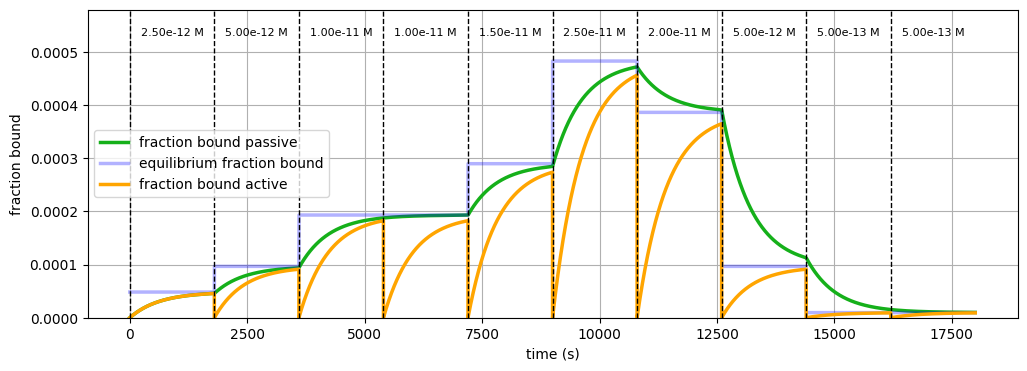

In [47]:
#IL-6 PBS:
# kon = 5.2e4 # 1/M*s
# koff = 2.84e-4 # 1/s

# IL-6 ISF:
kon = 3.11e4 # 1/M*s
koff = 1.61e-3 # 1/s

# TNF-alpha PBS:
# kon = 2.33e4
# koff = 1.22e-4

#TNF-alpha ISF:
# kon = 8.3e3 # 1/M*s
# koff = 3.38e-4 # 1/s



Kd = koff/kon # M
print("kon: ", kon, "koff: ", koff, "Kd: ", Kd)


target_profile_list = il6_figure5_concentration_profile_M #[[1e-13, 30], [1e-12, 30], [1e-11, 30], [7e-12, 30], [1e-13, 30]] # specify list of lists of pairs of target concentration and duration of that concentration

fraction_bound_passive = []
fraction_bound_active = []

timestep=0.5
x0 = [1, 0]
for step in target_profile_list:
    target = step[0] # M
    duration = step[1] # min
    _, _, traces = matrix_exponential_solution(T=target, kon=kon, koff= koff, x0=x0, dt=timestep, duration=duration)
    fraction_bound_passive.extend(traces[:,1].tolist())
    x0 = traces[-1,:]
    
x0 = [1, 0]
for step in target_profile_list:
    target = step[0] # M
    duration = step[1] # min
    _, _, traces = matrix_exponential_solution(T=target, kon=kon, koff= koff, x0=x0, dt=timestep, duration=duration)
    fraction_bound_active.extend(traces[:,1].tolist())
    x0 = [1,0]

plot_matrix_exponential_model(target_profile_list=target_profile_list, fraction_bound_passive=fraction_bound_passive, fraction_bound_active=fraction_bound_active, Kd=Kd, dt=timestep)

In [14]:
# Active Perspective Figure 2

50000.0

In [31]:
0.013/(1-0.013)

0.013171225937183383